# **1. Pengenalan**

---
## Hyperparameter

Hyperparameters adalah variabel-variabel yang ditentukan nilainya oleh pembuat model sebelum Training model dilakukan. Variabel-variabel ini bersifat konstan (tidak berubah nilainya) selama proses training sehingga berpengaruh pada model yang dihasilkan.

Hyperparameters pada desain model mencakup:
* model (architectural) hyperparameters:
  * degree of polynomial pada linear model
  * jumlah layer dan neuron pada Neural Network
  * jenis-jenis layer yang digunakan pada Deep Learning
  * dll.

* training (algorithm) hyperparameters:
  * nilai K pada Nearest Neighbors
  * learning rate pada Gradient Descent
  * regularization
  * dropout value
  * optimizer algorithm
  * batch size
  * dll

Pada Artificial Neural Network, bobot atau weights dari setiap node/neuron adalah parameter yang nilainya berubah-ubah selama training, tujuannya untuk mencari bobot-bobot terbaik sehingga menghasilkan model dengan performa yang paling baik.

---
## Optimization Approaches (Pendekatan-pendekatan Optimasi)

Ada beberapa pendekatan untuk melakukan Optimasi Hyperparameter. Beberapa pendekatan yang banyak dilakukan adalah:
* Traditional Grid Search
 * biasa digunakan untuk optimasi width, depth, dan types of layer in ANN
 * mencari K pada KNN or Kernel type pada SVMs
* Random Search
 * dapat digunakan untuk optimasi learning rate awalan
* Bayesian opmitization
 * dapat digunakan untuk optimasi learning rate awalan
* Evolutionary optimization


<table>
  <tr><td  align="center">
    <img src="https://images.ctfassets.net/be04ylp8y0qc/1m1AB8NPTcKkuEaqg2Zgyg/e56d45a2c85b99820ead8159a280323f/hp_tuning_flow_1f745fd5e0ae8830804bab6a66e2c917_1000.png" width="80%"
         alt="Hyperparameter tuning process">
  </td></tr>
  <tr><td align="center">
    <b>Figure:</b>Hyperparameter tuning process.<br/>
  </td></tr>
</table>


Grid Search optimization biasanya tergabung dengan skema K-Fold Cross-Validation, sedangkan sisanya menggunakan Hold-out validation. Terutama jika mempelajari data yang sangat besar, lebih baik menggunakan single validation daripada cross validation. Dalam kebanyakan kasus, satu set validasi dengan ukuran yang wajar menyederhanakan  kode secara substansial, tanpa perlu K-fold cross validation.

Untuk Neural Network dan Deep Learning, Hyperparameter Tuning dilakukan dengan menggunaka sedikit epoch untuk  mendapat kombinasi hyperparameter yang memiliki potensi yang paling baik untuk proses training tersebut.

# **2. Mounting Google Drive**

In [3]:
from google.colab import drive
from os.path import join, exists

# mounting dataset dari gdrive
drive.mount('/content/gdrive', force_remount=True)

# folder ini juga digunakan untuk menyimpan model yang sudah dilatih
root_path = 'gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak02_Data/'

# opsional - tampilkan info lokasi dataset
print("Path root:", root_path)

Mounted at /content/gdrive
Path root: gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak02_Data/


# **3.Download Dataset**
Kita menggunakan Fashion MNIST Dataset yang terdiri 10 kelas.


In [4]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

# download fashion mnist dataset
(X_data, y_data), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# kategori pada dataset
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# bagi data latih untuk mendapatkan data validasi dengan rasio 70% - 30%
X_train, X_val, y_train, y_val = train_test_split(X_data, y_data,
                                                  test_size=0.3,
                                                  random_state=42)

y_train = y_train.ravel()
y_val = y_val.ravel()
y_test = y_test.ravel()

# tampilkan informasi dataset
num_class = len(class_names)
print('Jumlah kelas:', num_class)
print('Label kelas:', class_names)
print('Dimensi data latih:', X_train.shape)
print('Dimensi data validasi:', X_val.shape)
print('Dimensi data uji:', X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Jumlah kelas: 10
Label kelas: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Dimensi data latih: (42000, 28, 28)
Dimensi data validasi: (18000, 28, 28)
Dimensi data uji: (10000, 28, 28)


## Visualisasi Data

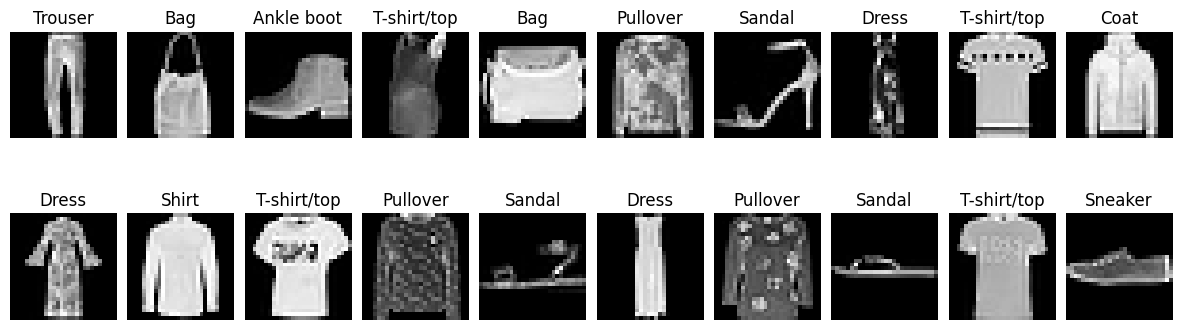

In [5]:
import matplotlib.pyplot as plt

%matplotlib inline

fig, ax = plt.subplots(2,10,figsize=(15,4.5))
fig.subplots_adjust(hspace=0.1, wspace=0.1)
for j in range(0,2):
    for i in range(0, 10):
        ax[j,i].imshow(X_train[i+j*10], cmap='gray')
        ax[j,i].set_title(class_names[y_train[i+j*10]])
        ax[j,i].axis('off')
plt.show()

# Persiapan Dataset
Lakukan normalisasi pada data citra dengan membagi dengan 255

In [6]:
# normalisasi data citra
X_train = X_train.astype('float32') / 255.
X_val   = X_val.astype('float32') / 255.
X_test  = X_test.astype('float32') / 255.

**Warning: Sebelumnya pastikan bahwa folder Google Drive untuk menyimpan model Tuner (file json Tuner dll) semuanya dikosongkan terlebih dahulu**

# **4. Keras Tuner**
Library untuk tuning hyperparameter
---
<img src = "https://tse1.mm.bing.net/th/id/OIP.wwnExqe720PPHykHhs5HqwHaCJ?rs=1&pid=ImgDetMain&o=7&rm=3" height="200" align = "center">

Keras tuner adalah library untuk hyperparameter optimization  (Hyperparameter tuner) dibangun khusus untuk `tf.keras` with TensorFlow 2.0. Library ini diperkenalkan pada Google I/O 2019 event.

Library ini ditujukan bagi praktisi AI, kreator algoritma hypertuner, dan desainer model. Membangun model dapat dilakukan dengan sangat mudah dengan API yang bersih dan mudah. ​​Keras Tuner dilengkapi dengan algoritma Bayesian Optimization, Hyperband, dan Random Search bawaan, dan juga dirancang agar mudah dikembangkan oleh para peneliti untuk bereksperimen dengan algoritma pencarian baru.

read more: [Documentation](https://keras-team.github.io/keras-tuner/), [github repository](https://github.com/keras-team/keras-tuner)

# 4.1 Instalasi

In [7]:
!pip install -q -U keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.6 MB/s eta 0:00:00


#4.2 Menentukan Range Nilai Hyperparameter

Pada contoh ini, kita hanya akan mengguankan Two-Layer Neural Network, dan kita akan 'tune' layer width (jumlah neuron dalam Hidden Layer), jenis fungsi aktivasi yang digunakan pada tiap layer, dan learning rate. Baik hyperparameter range maupun modelnya harus didefinisikan untuk dimasukkan pada method pada Tuner Object.

### Layer Width (Jumlah Neuron pada Hidden layer)

Untuk hyperparameter jumlah neuron pada Hidden Layer, akan digunakan grid choice untuk itrasi dari 128 ke 256 dengan langkah kenaikan 64. Oleh karena itu method `Int()` digunakan.

```python
    ch_unit = hp.Int('units', min_value=128, max_value=256, step=64)
```

### Activation Function
Untuk fungsi aktivasi,  `relu`, `tanh`, and `sigmoid` akan dicoba semua. Oleh karena itu fungsi `Choice()` akan digunakan sebagai berikut.
```python
    ch_activation = hp.Choice('activation', values=['relu', 'tanh', 'sigmoid'], default='relu')


### Learning Rate
Parameter 'learning rate' menunjukkan seberapa cepat algoritma learning pada neural network berprogress. 'Learning rate' mungkin merupakan hiperparameter terpenting yang harus dikonfigurasi untuk model neural network. Sayangnya,  laju pembelajaran optimal tidak dapat dihitung untuk model tertentu pada dataset tertentu. 'Learning rate' yang baik dapat diperoleh melalui proses uji coba.

Grid search sebenarnya bukan metode paling bagus untuk melakukan hyperparameter tuning. Sebagaimana disebutkan oleh Bergstra and Bengio dalam [Random Search for Hyper-Parameter Optimization](http://www.jmlr.org/papers/volume13/bergstra12a/bergstra12a.pdf), “percobaan secara random lebih efektif untuk hyperparameter tuning dibandingkan dengan Grid search”.

<table>
  <tr><td  align="center">
    <img src="https://cs231n.github.io/assets/nn3/gridsearchbad.jpeg" width="50%"
         alt="Grid vs Random Layout.">
  </td></tr>
  <tr><td align="center">
    <b>Figure:</b> Grid vs Random Layout illustration from [Random Search for Hyper-Parameter Optimization](http://www.jmlr.org/papers/volume13/bergstra12a/bergstra12a.pdf).
  </td></tr>
</table>

Biasanya, learning rate dipilih dalam sampling skala Log. Secara intuitif, ini karena learning rate memiliki beberapa efek multiplikatif pada training. Pengetahuan awal ini dapat dipergunakan dalam learning rate yang optimal melalui setting pada sampling method.

```python
    ch_learning_rate = hp.Float('learning_rate', min_value=1e-5, max_value=1e-2, sampling='LOG', default=1e-3)
```

# **5. Define Model**

Sekarang kita definisikan sebuah fungsi untuk membangun model. Kita masih menggunakan Keras API, tetapi kita inputkan pilihan-pilihan untuk nilai hyperparameter yang akan digunakan. Fungsi tsb menerima input 'hp' dimana kita dapat melakukan hyperparameter setting di situ.

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.optimizers import Adam

def build_model(hp):
    ch_unit          = hp.Int('units', min_value=128, max_value=256, step=64)
    ch_activation    = hp.Choice('activation', values=['relu', 'tanh', 'sigmoid'], default='relu')
    ch_learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='LOG', default=1e-3)

    # define model
    model = Sequential([
                Flatten(input_shape=(28,28)),
                Dense(units=ch_unit, activation=ch_activation),   # hidden layer 1
                Dense(10, activation='softmax')     # layer output
            ])

    # compile model
    model.compile(
        optimizer = Adam(learning_rate=ch_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])

    return model

## Model Post **Test**

In [33]:
def build_model(hp):
    # contoh konfigurasi ch_units
    ch_unit1         = hp.Int('units_1', min_value=64, max_value=512, step=64)
    ch_unit2         = hp.Int('units_2', min_value=64, max_value=512, step=64)
    ch_unit3         = hp.Int('units_3', min_value=64, max_value=512, step=64)
    ch_activation    = hp.Choice('activation', values=['relu', 'tanh', 'sigmoid'], default='relu')
    ch_learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='LOG', default=1e-3)

    # define model
    model = Sequential([
        Flatten(input_shape=(28,28)),
        Dense(units=ch_unit1, activation=ch_activation), # hidden layer 1
        Dense(units=ch_unit2, activation=ch_activation), # hidden layer 2
        Dense(units=ch_unit3, activation=ch_activation), # hidden layer 3
        Dense(10, activation='softmax') # layer output
    ])

    # compile model
    model.compile(
        optimizer = tf.keras.optimizers.Adam(ch_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])

    return model

# **6. Inisialisasi Tuner**
---
Keras Tuner memiliki empat jenis Tuner yaitu - **RandomSearch**, **Hyperband**,  **Bayesian Optimization** and **Sklearn**. Pada latihan ini, kita akan fokus pada random search dan Hyperband. Tuner Hyperband pada dasarnya berbasis Random Search, namun mengoptimasi Random Search dari sisi waktu.

Pada fungsi yang akan kita bangun, beberapa parameter dapat di-set, seperti nama `objective` (metrics) untuk optimasi, jumlah ujicoba (`max_trials`) untuk menge-test model, dan jumlah model yang dibangun dan diujicobakan (`executions_per_trial`) pada tiap eksekusi.

Mirip dengan K-Fold Cross Validation, Tujuan dari adanya beberapa eksekusi per percobaan adalah untuk mengurangi variansi hasil dan oleh karena itu dapat menilai kinerja model dengan lebih akurat.



In [9]:
!pip install -q -U keras-tuner


In [10]:
import keras_tuner as kt

In [11]:
from keras_tuner import RandomSearch, Hyperband

---
## 6.1 - Random Search Tuner
Cara paling intuitif untuk melakukan hyperparameter tuning adalah mencoba kombinasi nilai-nilai hyperparameter kemudian menguji nya.

### Inisialisasi Random Tuner


Di sini kita akan melakukan eksperimen tuning sebanyak 4 kali, dengan seleksi model terbaik berdasarkan validation accuracy. Variabel 'max_trials' merepresentasikan jumlah kombinasi hyperparameter yang akan diujicobakan oleh tuner, sedangkan variabel 'execution_per_trial' merupakah jumlah model yang seharusnya dibangun dan digunakan untuk ujicoba di setiap eksekusi.

In [35]:
tuner_random = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=4,
    executions_per_trial=2,
    directory=join(root_path, 'random_search_post_test'),
    project_name='mnist_random'
    )

Setelah model dan tuner di-set up, kita dapat melihat ringkasan proses/space pencarian hyperparameter nya

In [36]:
tuner_random.search_space_summary()

Search space summary
Default search space size: 5
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
units_2 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
units_3 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh', 'sigmoid'], 'ordered': False}
learning_rate (Float)
{'default': 0.001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


### Jalankan Proses Random Tuning

Sekarang kita dapat memulai Optimization untuk 5 epochs. Argumen yang digunakan sama seperti pada `tf.keras.model.fit`

Tergantung dari besarnya ruang/space pencarian hyperparameter terbaik, proses pencarian hyperparameter terbaik ini memerlukan waktu.

In [37]:
tuner_random.search(X_train, y_train,
             batch_size=256,
             epochs=5,
             validation_data=(X_val, y_val))

Trial 4 Complete [00h 00m 42s]
val_accuracy: 0.8456944525241852

Best val_accuracy So Far: 0.8706944584846497
Total elapsed time: 00h 03m 01s


### Melihat Hasil Pencarian

Akhirnya, hasil dari pencarian dapat dirangkum sebagai berikut.



In [38]:
tuner_random.results_summary()


Results summary
Results in gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak02_Data/random_search_post_test/mnist_random
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
units_1: 384
units_2: 384
units_3: 384
activation: relu
learning_rate: 0.0014194016660592278
Score: 0.8706944584846497

Trial 0 summary
Hyperparameters:
units_1: 384
units_2: 128
units_3: 64
activation: tanh
learning_rate: 0.00027398244095838686
Score: 0.8686944246292114

Trial 2 summary
Hyperparameters:
units_1: 320
units_2: 64
units_3: 448
activation: relu
learning_rate: 0.00018695828948093836
Score: 0.8622777760028839

Trial 3 summary
Hyperparameters:
units_1: 448
units_2: 64
units_3: 192
activation: tanh
learning_rate: 0.00709227280158967
Score: 0.8456944525241852


### Tampilkan Hyperparameter Terbaik


In [39]:
import tensorflow.keras.backend as K

# Retrieve the best model.
best_model_random = tuner_random.get_best_models(num_models=1)[0]
best_model_random.summary()

print('Best Initial Learning Rate =', K.eval(best_model_random.optimizer.learning_rate))
print('Activation Function used   =', best_model_random.layers[1].get_config()['activation'])

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 384)            │       301,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 384)            │       147,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 384)            │       147,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         3,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 600,970 (2.29 MB)

 Trainable params: 600,970 (2.29 MB)

 Non-trainable params: 0 (0.00 B)

Best Initial Learning Rate = 0.0014194016
Activation Function used   = relu


### Menampilkan arsitektur model dengan nilai Hyperparameter yang terbaik (paling optimal dan menghasilkan akurasi terbaik)

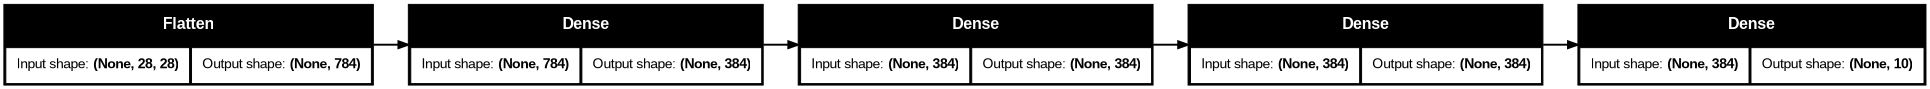

In [40]:
from tensorflow.keras.utils import plot_model

plot_model(best_model_random,
           to_file='best_random.png',
           show_shapes=True,
           show_layer_names=False,
           rankdir='LR',
           dpi=70
          )

---
## 6.2 - Hyperband Tuner
Hyperband adalah versi 'optimized' dari random search yang menggunakan early stopping untuk mempercepat proses Hyperparameter Tuning. Algoritma Hyperband tuning juga menggunakan alokasi resource secara dinamis dan early-stopping untuk mempercepat konvergensi pada proses hyperparameter tuning.

Ide utamanya adalah untuk menyesuaikan model-model dengan jumlah banyak untuk epoch yang kecil dan hanya melanjutkan pelatihan untuk model yang mencapai akurasi tertinggi pada validation set. Variabel `max_epochs` adalah jumlah maksimum epoch yang dapat digunakan untuk melatih model.

### Inisialisasi Hyperband Tuner
Kita akan melakukan eksperimen sebanyak 4 kali, dengan seleksi model terbaik berdasarkan validation accuracy.

In [41]:
tuner_hyperband = Hyperband(
    build_model,
    max_epochs=5,
    objective='val_accuracy',
    executions_per_trial=2,
    directory=join(root_path, 'hyperband_post_test'),
    project_name='mnist_hyperband'
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Setelah model dan tuner di-setup, kita dapat melihat ringkasan space pencarian nilai hyperparameter

In [42]:
tuner_hyperband.search_space_summary()

Search space summary
Default search space size: 5
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
units_2 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
units_3 (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 512, 'step': 64, 'sampling': 'linear'}
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh', 'sigmoid'], 'ordered': False}
learning_rate (Float)
{'default': 0.001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


## Run Hyperband Tuning

Kita dapat mulai melakukan optimasi Hyperparameter dengan 5 epochs

In [43]:
tuner_hyperband.search(X_train, y_train,
             batch_size=256,
             epochs=5,
             validation_data=(X_val, y_val))

Trial 10 Complete [00h 00m 43s]
val_accuracy: 0.8733611106872559

Best val_accuracy So Far: 0.8762499988079071
Total elapsed time: 00h 05m 10s


### Melihat Hasil Ringkasan Pencarian

Berikut Summary dari pencarian nilai Hyperparameter terbaik. Akhirnya hasil pencarian nilai Hyperparameter dapat digunakan

In [44]:
tuner_hyperband.results_summary()

Results summary
Results in gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak02_Data/hyperband_post_test/mnist_hyperband
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0006 summary
Hyperparameters:
units_1: 512
units_2: 192
units_3: 384
activation: relu
learning_rate: 0.0008161739188324943
tuner/epochs: 5
tuner/initial_epoch: 2
tuner/bracket: 1
tuner/round: 1
tuner/trial_id: 0004
Score: 0.8762499988079071

Trial 0007 summary
Hyperparameters:
units_1: 384
units_2: 384
units_3: 64
activation: relu
learning_rate: 0.0012422772048365925
tuner/epochs: 5
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.8757499754428864

Trial 0009 summary
Hyperparameters:
units_1: 448
units_2: 64
units_3: 64
activation: relu
learning_rate: 0.00038305416753732047
tuner/epochs: 5
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.8733611106872559

Trial 0005 summary
Hyperparameters:
units_1: 512
units_2: 64
units_3: 320
activation: tanh
learning_ra

## Melihat Parameter Terbaik
Hasil parameter tuning yang terbaik (validation accuracy tertinggi) adalah sebagai berikut.

In [46]:
best_hps=tuner_hyperband.get_best_hyperparameters(num_trials=1)[0]
print(f"""
The hyperparameter search is complete. Jumlah unit pada Dense layer pertama adalah {best_hps.get('units_1')} dan nilai learning_rate yang paling optimal adalah {best_hps.get('learning_rate')}.
""")


The hyperparameter search is complete. Jumlah unit pada Dense layer pertama adalah 512 dan nilai learning_rate yang paling optimal adalah 0.0008161739188324943.



## Melihat Hasil Optimasi dengan Akurasi Terbaik

In [47]:
# Retrieve the best model.
best_model_hyperband = tuner_hyperband.get_best_models(num_models=1)[0]
best_model_hyperband.summary()

print('Best Initial Learning Rate =', K.eval(best_model_hyperband.optimizer.learning_rate)) ##ini ada salah penyebutan library learning rate
print('Activation Function used   =', best_model_random.layers[1].get_config()['activation'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 192)            │        98,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 384)            │        74,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         3,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 578,378 (2.21 MB)

 Trainable params: 578,378 (2.21 MB)

 Non-trainable params: 0 (0.00 B)

Best Initial Learning Rate = 0.0008161739
Activation Function used   = relu


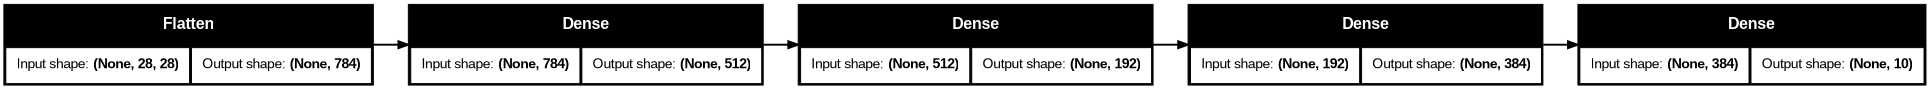

In [48]:
from tensorflow.keras.utils import plot_model

plot_model(best_model_hyperband,
           to_file='best_hyperband.png',
           show_shapes=True,
           show_layer_names=False,
           rankdir='LR',
           dpi=70
          )

# **7. Model Evaluation**

Model dengan hyperparameter hasil dari tuning dengan Random Search

In [49]:
loss, accuracy = best_model_random.evaluate(X_test, y_test)
print('Validation Accuracy (Random Search) =', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8627 - loss: 0.3768
Validation Accuracy (Random Search) = 0.8626999855041504


Model hasil dari tuning dengan Hyperband

In [50]:
loss, accuracy = best_model_hyperband.evaluate(X_test, y_test)
print('Validation Accuracy (Hyperband) =', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8688 - loss: 0.3696
Validation Accuracy (Hyperband) = 0.8687999844551086


### View Result
Visualisasi dari Hasil Prediksi Model

Hasil prediksi model dari tuning dengan Random Search

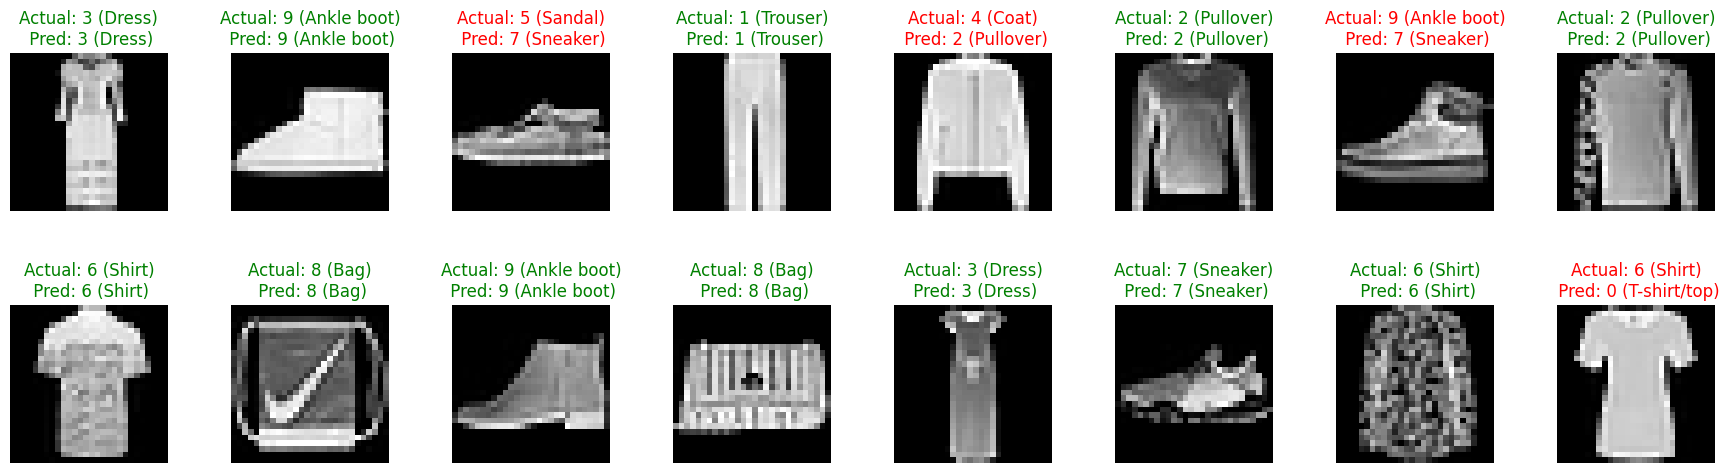

In [51]:
y_pred = best_model_random.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred, axis=1)

fig, ax = plt.subplots(2,8,figsize=(22,6))
fig.subplots_adjust(hspace=0.2, wspace=0.4)

for j in range(0,2):
    for i in range(0, 8):

        img_index = np.random.randint(0, X_test.shape[0])
        ax[j,i].imshow(X_test[img_index], cmap='gray')

        actual_label    = int(y_test[img_index])
        predicted_label = int(y_pred[img_index])

        color = 'red'
        if actual_label == predicted_label:
            color = 'green'

        ax[j,i].set_title("Actual: {} ({})\n Pred: {} ({})".format(
            actual_label, class_names[actual_label], predicted_label, class_names[predicted_label]
            ), color=color)
        ax[j,i].axis('off')
plt.show()

Hasil prediksi model dari tuning dengan Hyperband

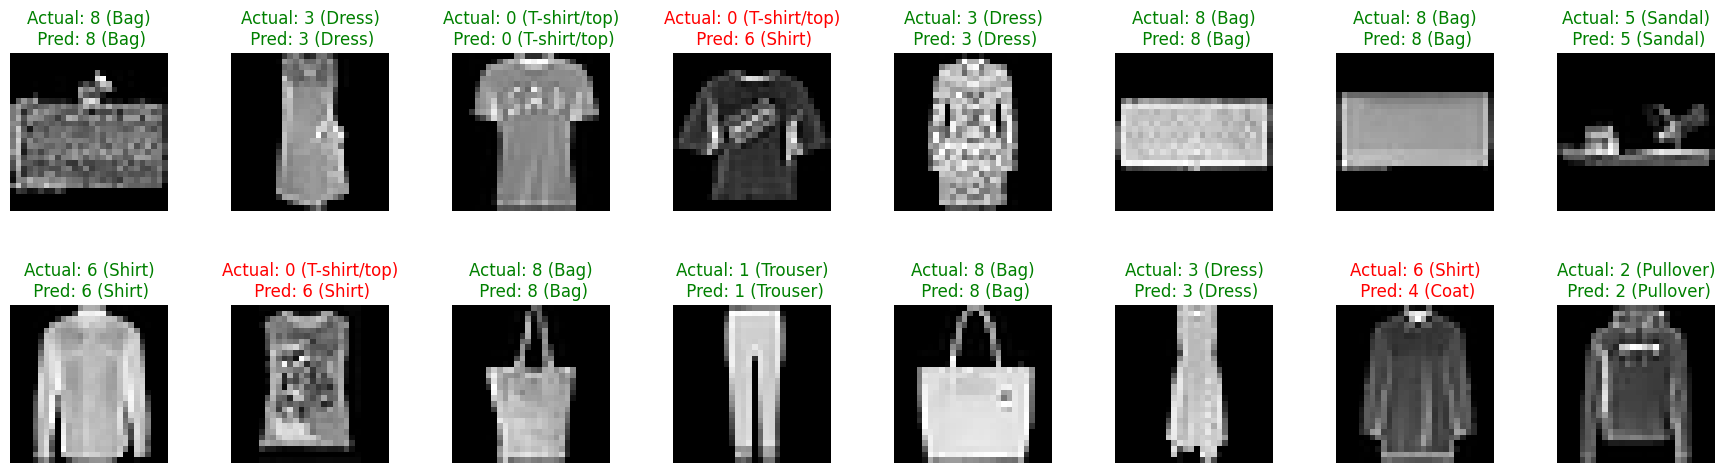

In [52]:
y_pred = best_model_hyperband.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred, axis=1)

fig, ax = plt.subplots(2,8,figsize=(22,6))
fig.subplots_adjust(hspace=0.2, wspace=0.4)

for j in range(0,2):
    for i in range(0, 8):

        img_index = np.random.randint(0, X_test.shape[0])
        ax[j,i].imshow(X_test[img_index], cmap='gray')

        actual_label    = int(y_test[img_index])
        predicted_label = int(y_pred[img_index])

        color = 'red'
        if actual_label == predicted_label:
            color = 'green'

        ax[j,i].set_title("Actual: {} ({})\n Pred: {} ({})".format(
            actual_label, class_names[actual_label], predicted_label, class_names[predicted_label]
            ), color=color)
        ax[j,i].axis('off')
plt.show()

# **8. Post-Test**
1. Copy kode di bagian **5. Define Model** yang sudah anda perbaiki
2. Buat teks baru dibawah kode bagian 5. Define Model tersebut dan diisi dengan teks **Model Post Test**
3. Buat kode baru dibawah teks tersebut lalu paste kode dari bagian 5 di soal nomor 1 tadi.
4. **Tambahkan 2 hidden layer** setelah hidden layer pertama dan sebelum layer output.
5. **Ubah rentang pencarian nilai hyperparameter dari ch_units** yang ada di kode tersebut. Karena sekarang total ada 3 hidden layer maka buat 3 ch_units dengan konfigurasi yang berbeda. Beri nama 'units_1', 'units_2', dan 'units_3' seperti pada contoh kode.
6. Kira-kira menjadi seperti kode dibawah ini. Anda lengkapi kode yang masih tanda tanya '???'.
```python
def build_model(hp):
    # contoh konfigurasi ch_units
    ch_unit1         = hp.Int('units_1', min_value=64, max_value=512, step=64)
    ch_unit2         = ???
    ch_unit3         = ???
    ch_activation    = ???
    ch_learning_rate = ???

    # define model
    model = Sequential([
                Flatten(input_shape=(28,28)),
                Dense(units=???, activation=???), # hidden layer 1
                Dense(units=???, activation=???), # hidden layer 2
                Dense(units=???, activation=???), # hidden layer 3
                Dense(10, activation='softmax') # layer output
            ])

    # compile model
    model.compile(
        optimizer = tf.keras.optimizers.Adam(???),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    
    return model
```
6. Jalankan kode di bagian Model Post Test tersebut.
7. **Modifikasi bagian 6.1 - Initialize Random Tuner**. Ubah lokasi penyimpanan model hasil pelatihan dari **'random_search' menjadi 'random_search_post_test'**
```python
tuner_random = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=4,
    executions_per_trial=2,
    directory=join(root_path, 'random_search'), # << ubah bagian ini
    project_name='mnist_random'
    )
```
8. **Modifikasi bagian 6.2 - Initialize Hyperband Tuner**. Ubah lokasi penyimpanan model hasil pelatihan dari **'hyperband' menjadi 'hyperband_post_test'**
```python
tuner_hyperband = Hyperband(
    build_model,
    max_epochs=5,
    objective='val_accuracy',
    executions_per_trial=2,
    directory=join(root_path, 'hyperband'),  # << ubah bagian ini
    project_name='mnist_hyperband'
)
```
9. Jalankan semua kode di bagian 6 dan 7.
10. Amati hasil akurasi pengujiannya dan hasil prediksinya!

### **Kesimpulan Analisis Post-Test: Hyperband vs Random Search**

Berdasarkan hasil eksperimen pencarian hyperparameter (*hyperparameter tuning*) pada model Neural Network 3-layer menggunakan dataset Fashion MNIST, didapatkan kesimpulan perbandingan sebagai berikut:

#### **1. Efisiensi Waktu & Penggunaan Resource**
* **Random Search**:
  * Menguji seluruh kombinasi secara merata tanpa proses eliminasi dini (*early stopping*).
  * Membutuhkan waktu total sekitar **3 menit 1 detik** untuk menyelesaikan seluruh uji coba.
* **Hyperband**:
  * Menggunakan alokasi sumber daya secara adaptif dan melakukan eliminasi dini (*early stopping*) pada kombinasi parameter dengan performa buruk di epoch awal.
  * Membantu memfokuskan komputasi hanya pada kandidat model yang paling menjanjikan.

#### **2. Perbandingan Performa Akurasi (Test Set)**
* **Validation Accuracy (Random Search)**: **86.27%**
* **Validation Accuracy (Hyperband)**: **86.88%**

*Hyperband berhasil menemukan kombinasi parameter yang menghasilkan akurasi yang lebih tinggi di data uji dibandingkan dengan metode Random Search.*

#### **3. Konfigurasi Parameter Terbaik yang Ditemukan**
* **Hyperband (Terbaik)**:
  * Arsitektur Hidden Layer: **[512, 192, 384]**
  * Fungsi Aktivasi: **`relu`**
  * Learning Rate: **0.000816**
  * Akurasi Validasi Terbaik: **87.62%**
* **Random Search**:
  * Arsitektur Hidden Layer: **[384, 384, 384]**
  * Fungsi Aktivasi: **`relu`**
  * Learning Rate: **0.001419**
  * Akurasi Validasi Terbaik: **87.06%**

#### **Kesimpulan Akhir**
**Hyperband terbukti jauh lebih unggul dan efisien** dibandingkan Random Search konvensional. Melalui mekanisme pemangkasan trial yang tidak potensial (*bracket-based early stopping*), Hyperband dapat menguji ruang pencarian (*search space*) yang lebih dinamis dan menghasilkan akurasi final yang lebih tinggi (86.88% vs 86.27%) dengan efektivitas waktu yang lebih baik.